# 🔬 Applied Vision Transformer: recognising underwater litter with ViT-B/16
**MAAI901 Deep Learning for Visual Data · Applied Vision Transformer Report (individual)**

A **Vision Transformer (ViT-B/16)** is fine-tuned to classify objects seen by deep-sea robots (ROVs) in the **TrashCan 1.0** dataset (Hong, Fulton & Sattar, 2020) into **trash**, **bio** (marine life) and **rov** (the robot's own equipment).

| Step | Report section | What it does | Time (T4) |
|---|---|---|---|
| 1 | – | Setup: GPU, Google Drive, find files, unzip, install | ~3 min |
| 2 | Dataset & pre-processing | Cut every labelled object out of the images, video-level split, statistics, sample figure | ~2 min |
| 3 | Model selection & configuration | Load ViT-B/16 (ImageNet pre-trained), show its configuration | <1 min |
| 4 | Training (baseline) | **Frozen ViT + linear classifier** (embedding extraction) | ~3 min |
| 5 | Training / fine-tuning | **Full fine-tuning** of ViT-B/16, training curves | ~10 min |
| 6 | Evaluation | Test metrics, confusion matrices, comparison table | <1 min |
| 7 | Performance & bias analysis | Accuracy by object size, image clarity and video | <1 min |
| 8 | Explainability | Attention maps (where the ViT looks) and its mistakes | ~1 min |
| 9 | (optional) | CLIP zero-shot comparison (multimodal, no training) | ~2 min |
| 10 | – | Export the model and examples for the web app | <1 min |

**Web app:** Streamlit, code at [github.com/navidharshan1-cpu/vit-underwater-litter](https://github.com/navidharshan1-cpu/vit-underwater-litter); model weights in its Release `v1.0`.

**How to run:** `Runtime → Change runtime type → T4 GPU → Save`, then `Runtime → Run all`.
**Files needed in My Drive:** the TrashCan `dataset.zip` (any name, ~528 MB) and `video_split.json`.
Results and figures are saved to **Google Drive → OceanWatch → vit_report**.

## 1. Setup

In [1]:
# ===== 1. Setup: GPU, Google Drive, files, install =====
import os, sys, subprocess, importlib.util
from pathlib import Path
import torch

if torch.cuda.is_available():
    print('GPU OK:', torch.cuda.get_device_name(0))
else:
    print('WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU (training on CPU would take hours).')
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

from google.colab import drive
drive.mount('/content/drive')
DRIVE, WORK = Path('/content/drive/MyDrive'), Path('/content')
OUTDIR = DRIVE / 'OceanWatch' / 'vit_report'
OUTDIR.mkdir(parents=True, exist_ok=True)

def find(pattern, max_depth=4):
    hits = []
    for root, dirs, files in os.walk(DRIVE):
        if len(Path(root).relative_to(DRIVE).parts) >= max_depth:
            dirs[:] = []
        hits += [Path(root) / f for f in files if Path(f).match(pattern)]
    return sorted(hits)

zips = [p for p in find('*.zip') if 450e6 < p.stat().st_size < 600e6]
assert zips, 'TrashCan dataset zip (~528 MB) not found in My Drive.'
ZIP = sorted(zips, key=lambda p: 'plastic' not in p.name.lower())[0]
splits = find('video_split*.json')
assert splits, 'video_split.json not found in My Drive.'
SPLIT_FILE = splits[0]
print('Dataset zip:', ZIP, '\nSplit file :', SPLIT_FILE)

if not list((WORK / 'trashcan').rglob('instance_version')):
    print('Unzipping (1-5 minutes)...')
    subprocess.run(['unzip', '-oq', str(ZIP), '-d', str(WORK / 'trashcan')], check=True)
SRC = next((WORK / 'trashcan').rglob('instance_version'))

for pkg in ('transformers', 'sklearn'):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn' if pkg == 'sklearn' else pkg], check=True)
import transformers
print('transformers', transformers.__version__, '| torch', torch.__version__)

GPU OK: Tesla T4
Mounted at /content/drive
Dataset zip: /content/drive/MyDrive/plastic trash dataset.zip 
Split file : /content/drive/MyDrive/OceanWatch/video_split.json
Unzipping (1-5 minutes)...
transformers 5.20.2 | torch 2.11.0+cu130


## 2. Dataset and pre-processing
**Dataset.** TrashCan 1.0: 7,212 frames from JAMSTEC deep-sea ROV videos with box and mask annotations. Every annotated object is cut out (with 10% surrounding context) to make an **object-classification** dataset. The 22 TrashCan classes are merged into the annotators' three top-level labels: **trash**, **bio** (animals and plants) and **rov** (the robot's own parts).

**Leak-free split.** Frames are taken once per second from videos, so neighbouring frames are near-duplicates, and the official split shares 113 of its 115 test videos with training. Whole **videos** are therefore assigned to train / val / test (70 / 15 / 15), using `video_split.json`.

**Pre-processing for ViT.** Each crop is resized to **224 × 224** and normalised with mean = std = 0.5 (as in ViT pre-training). Training images are augmented with random resized crops (scale 0.7–1), horizontal flips and colour jitter, which simulates the varying light and turbidity under water. Boxes smaller than 8 px are skipped.

Object crops per class and split:

split  train   val  test
label                   
trash   4159   954   873
bio     1940   353   498
rov     2288   405   604
total   8387  1712  1975

Videos: train 203, val 51, test 56 (no video in more than one split)
Object size (sqrt of box area): median 79 px, 17% smaller than 32 px


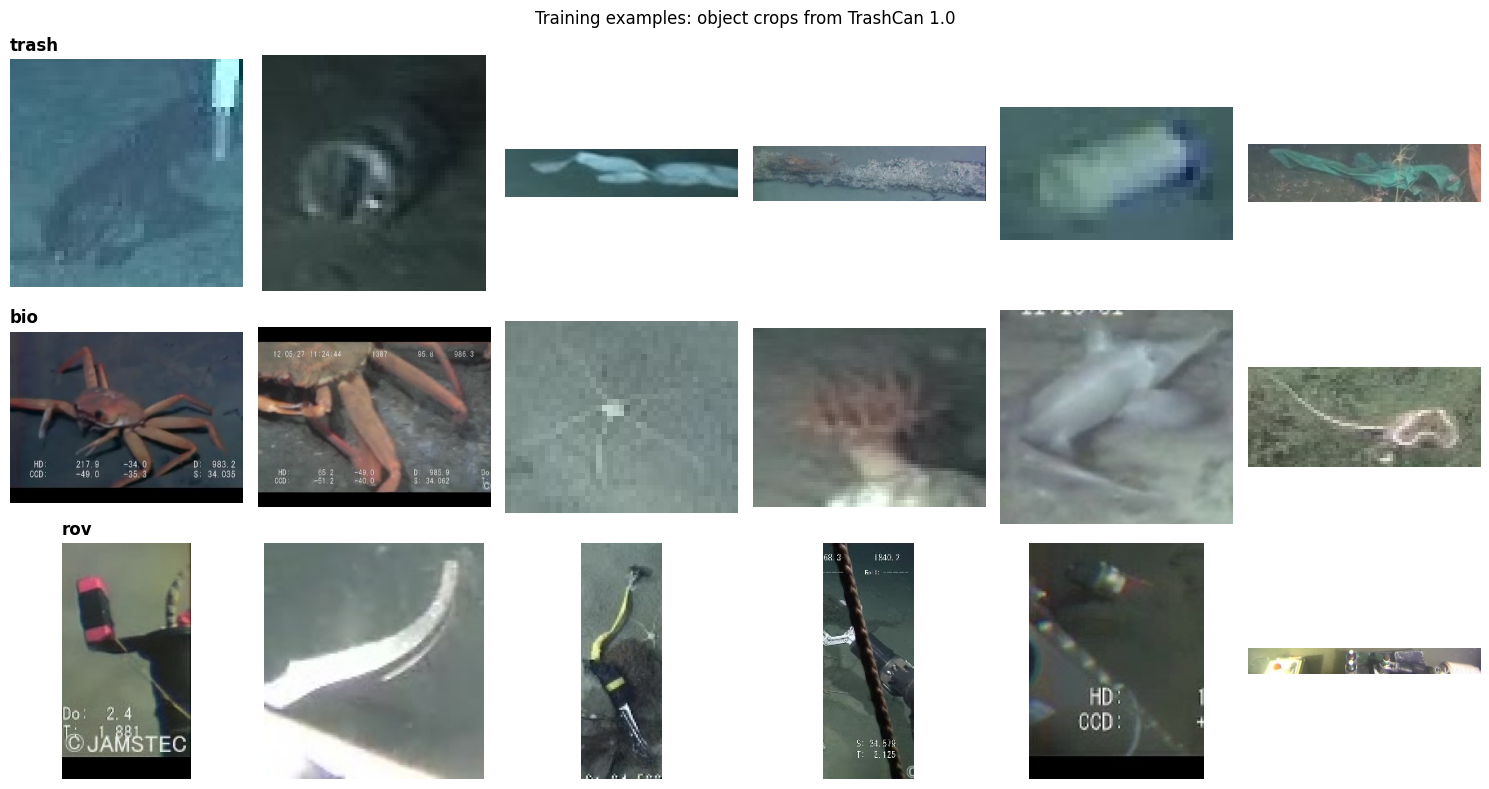

In [2]:
# ===== 2. Build the object-crop dataset (same video-level split) =====
import json, re, shutil, collections, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt

NAMES = ['trash', 'bio', 'rov']
CROPS, PAD, MIN_SIDE = WORK / 'crops', 0.10, 8

def video_of(file_name):
    m = re.match(r'(vid_\d+)', os.path.basename(file_name))
    return m.group(1) if m else Path(file_name).stem

def coarse(name):
    return 2 if name == 'rov' else 0 if name.startswith('trash') else 1

assign = json.loads(SPLIT_FILE.read_text())
META = CROPS / 'meta.csv'
if not META.exists():
    if CROPS.exists():
        shutil.rmtree(CROPS)
    rows = []
    for folder in ('train', 'val'):                       # pool the official files, re-split by video
        coco = json.loads((SRC / f'instances_{folder}_trashcan.json').read_text())
        cls = {c['id']: coarse(c['name']) for c in coco['categories']}
        anns = collections.defaultdict(list)
        for a in coco['annotations']:
            anns[a['image_id']].append(a)
        for im in coco['images']:
            if not anns[im['id']]:
                continue
            v = video_of(im['file_name'])
            split = assign[v]
            img = cv2.imread(str(SRC / folder / os.path.basename(im['file_name'])))
            H, W = img.shape[:2]
            contrast = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).std() / 255     # RMS contrast of the whole frame
            for a in anns[im['id']]:
                x, y, w, h = a['bbox']
                if w < MIN_SIDE or h < MIN_SIDE:
                    continue
                x0, x1 = int(max(0, x - PAD * w)), int(min(W, x + w + PAD * w))
                y0, y1 = int(max(0, y - PAD * h)), int(min(H, y + h + PAD * h))
                k = cls[a['category_id']]
                d = CROPS / split / NAMES[k]
                d.mkdir(parents=True, exist_ok=True)
                f = d / f"{Path(im['file_name']).stem}_{a['id']}.jpg"
                cv2.imwrite(str(f), img[y0:y1, x0:x1], [cv2.IMWRITE_JPEG_QUALITY, 95])
                rows.append({'file': str(f), 'split': split, 'label': k, 'video': v,
                             'box_w': w, 'box_h': h, 'frame_contrast': contrast})
    pd.DataFrame(rows).to_csv(META, index=False)

meta = pd.read_csv(META)
meta['size'] = np.sqrt(meta.box_w * meta.box_h)                # object size in pixels (sqrt of box area)
DATA = {s: (meta[meta.split == s].file.tolist(), meta[meta.split == s].label.to_numpy()) for s in ('train', 'val', 'test')}

counts = pd.crosstab(meta.label.map(dict(enumerate(NAMES))), meta.split).reindex(index=NAMES, columns=['train', 'val', 'test'], fill_value=0)
counts.loc['total'] = counts.sum()
print('Object crops per class and split:\n'); print(counts)
print(f"\nVideos: train {meta[meta.split=='train'].video.nunique()}, val {meta[meta.split=='val'].video.nunique()}, "
      f"test {meta[meta.split=='test'].video.nunique()} (no video in more than one split)")
print(f"Object size (sqrt of box area): median {meta['size'].median():.0f} px, "
      f"{(meta['size'] < 32).mean():.0%} smaller than 32 px")
counts.to_csv(OUTDIR / 'dataset_counts.csv')

# Figure: sample crops per class
rng = np.random.default_rng(0)
fig, axes = plt.subplots(3, 6, figsize=(15, 8))
for k, row in enumerate(axes):
    pick = rng.choice(meta[(meta.split == 'train') & (meta.label == k)].file.to_numpy(), 6, replace=False)
    for ax, f in zip(row, pick):
        ax.imshow(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)); ax.axis('off')
    row[0].set_title(NAMES[k], loc='left', fontsize=12, fontweight='bold')
plt.suptitle('Training examples: object crops from TrashCan 1.0'); plt.tight_layout()
plt.savefig(OUTDIR / 'fig1_dataset_samples.png', dpi=150, bbox_inches='tight'); plt.show()

## 3. Model selection and configuration
**ViT-B/16** (Dosovitskiy et al., 2021): the image is split into 16 × 16 patches (14 × 14 = 196 patches at 224 px), each patch becomes a token, and 12 transformer layers with self-attention relate every patch to every other patch. A [CLS] token summarises the image for classification. We start from weights pre-trained on ImageNet-21k and fine-tuned on ImageNet-1k (`google/vit-base-patch16-224`), and replace the 1,000-class head with a 3-class head.

Why ViT: global self-attention can use context around an object (seabed, the robot's arm) instead of only local texture, and large-scale pre-training transfers well to small specialised datasets.

In [3]:
# ===== 3. Load ViT-B/16 and show its configuration =====
from transformers import ViTForImageClassification, ViTModel

VIT_ID = 'google/vit-base-patch16-224'
def load_vit():
    kw = dict(num_labels=len(NAMES), ignore_mismatched_sizes=True,
              id2label=dict(enumerate(NAMES)), label2id={n: i for i, n in enumerate(NAMES)})
    try:
        return ViTForImageClassification.from_pretrained(VIT_ID, attn_implementation='eager', **kw)  # eager = attention maps
    except TypeError:
        return ViTForImageClassification.from_pretrained(VIT_ID, **kw)

vit = load_vit().to(dev)
c = vit.config
print(f'Model            : {VIT_ID}')
print(f'Image size/patch : {c.image_size} px / {c.patch_size} px  -> {(c.image_size // c.patch_size) ** 2} patches + [CLS]')
print(f'Layers / heads   : {c.num_hidden_layers} transformer layers, {c.num_attention_heads} attention heads')
print(f'Hidden size      : {c.hidden_size} (MLP {c.intermediate_size})')
print(f'Parameters       : {sum(p.numel() for p in vit.parameters()) / 1e6:.1f} M')
print(f'Output classes   : {c.id2label}')

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Model            : google/vit-base-patch16-224
Image size/patch : 224 px / 16 px  -> 196 patches + [CLS]
Layers / heads   : 12 transformer layers, 12 attention heads
Hidden size      : 768 (MLP 3072)
Parameters       : 85.8 M
Output classes   : {0: 'trash', 1: 'bio', 2: 'rov'}


## 4. Baseline: frozen ViT + linear classifier (embedding extraction)
The pre-trained ViT is used as a fixed feature extractor: each crop's [CLS] embedding (768 numbers) is extracted and a logistic-regression classifier is trained on top. This shows how much the ImageNet features already know about underwater objects, before any fine-tuning.

In [4]:
# ===== 4. Frozen ViT embeddings + logistic regression =====
import torchvision.transforms as TT
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, classification_report, confusion_matrix

norm = TT.Normalize([0.5] * 3, [0.5] * 3)
TF_TRAIN = TT.Compose([TT.RandomResizedCrop(224, scale=(0.7, 1.0)), TT.RandomHorizontalFlip(),
                       TT.ColorJitter(0.3, 0.3, 0.2), TT.ToTensor(), norm])
TF_EVAL = TT.Compose([TT.Resize((224, 224)), TT.ToTensor(), norm])

class Crops(Dataset):
    def __init__(self, split, tf):
        self.files, self.labels, self.tf = DATA[split][0], DATA[split][1], tf
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        return self.tf(Image.open(self.files[i]).convert('RGB')), int(self.labels[i])

def loader(split, tf, shuffle=False, bs=64):
    return DataLoader(Crops(split, tf), batch_size=bs, shuffle=shuffle, num_workers=2, pin_memory=True)

RESULTS = {}
def record(name, pred):
    y = DATA['test'][1]
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)
    RESULTS[name] = dict(pred=np.asarray(pred), acc=accuracy_score(y, pred), f1=f1_score(y, pred, average='macro'),
                         precision=p, recall=r, f1_class=f)
    print(f'\n=== {name}: test accuracy {RESULTS[name]["acc"]:.3f}, macro F1 {RESULTS[name]["f1"]:.3f} ===')
    print(classification_report(y, pred, labels=[0, 1, 2], target_names=NAMES, digits=3, zero_division=0))

@torch.no_grad()
def embed(split):
    vit.eval()
    out = []
    for x, _ in loader(split, TF_EVAL, bs=128):
        with torch.autocast(dev, dtype=torch.float16, enabled=(dev == 'cuda')):
            h = vit.vit(pixel_values=x.to(dev)).last_hidden_state[:, 0]     # [CLS] token
        out.append(h.float().cpu())
    return torch.cat(out).numpy()

print('Extracting frozen ViT embeddings...')
EMB = {s: embed(s) for s in DATA}
best = None
for C in [0.01, 0.03, 0.1, 0.3, 1, 3]:
    clf = LogisticRegression(C=C, max_iter=5000, class_weight='balanced').fit(EMB['train'], DATA['train'][1])
    f = f1_score(DATA['val'][1], clf.predict(EMB['val']), average='macro')
    print(f'  C={C:<5} validation macro F1 {f:.3f}')
    if best is None or f > best[0]:
        best = (f, C, clf)
print(f'Chosen C = {best[1]} (best on validation)')
record('ViT frozen + linear', best[2].predict(EMB['test']))

Extracting frozen ViT embeddings...
  C=0.01  validation macro F1 0.740
  C=0.03  validation macro F1 0.734
  C=0.1   validation macro F1 0.719
  C=0.3   validation macro F1 0.713
  C=1     validation macro F1 0.696
  C=3     validation macro F1 0.694
Chosen C = 0.01 (best on validation)

=== ViT frozen + linear: test accuracy 0.808, macro F1 0.808 ===
              precision    recall  f1-score   support

       trash      0.808     0.758     0.783       873
         bio      0.793     0.755     0.774       498
         rov      0.818     0.924     0.868       604

    accuracy                          0.808      1975
   macro avg      0.807     0.812     0.808      1975
weighted avg      0.808     0.808     0.806      1975



## 5. Fine-tuning ViT-B/16
All 86 M weights are trained end-to-end with **AdamW** (learning rate 3e-5, weight decay 0.05, one-cycle schedule with 10% warm-up), batch 32, **5 epochs**, mixed precision. The loss is **class-weighted cross-entropy**, because trash crops outnumber the other classes. The checkpoint with the best **validation macro F1** is kept; the test set is used only once, at the end.

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224
Key               | Status   |                                                                                          
------------------+----------+------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


epoch 1/5  loss 0.4267  train acc 0.818  val acc 0.795  val macro F1 0.741  (102s)
epoch 2/5  loss 0.0780  train acc 0.972  val acc 0.782  val macro F1 0.770  (103s)
epoch 3/5  loss 0.0277  train acc 0.991  val acc 0.808  val macro F1 0.774  (101s)
epoch 4/5  loss 0.0153  train acc 0.995  val acc 0.817  val macro F1 0.789  (102s)
epoch 5/5  loss 0.0120  train acc 0.997  val acc 0.813  val macro F1 0.784  (101s)

Best epoch 4 (validation macro F1 0.789)

=== ViT fine-tuned: test accuracy 0.856, macro F1 0.855 ===
              precision    recall  f1-score   support

       trash      0.847     0.834     0.841       873
         bio      0.920     0.759     0.832       498
         rov      0.830     0.969     0.894       604

    accuracy                          0.856      1975
   macro avg      0.866     0.854     0.855      1975
weighted avg      0.860     0.856     0.855      1975



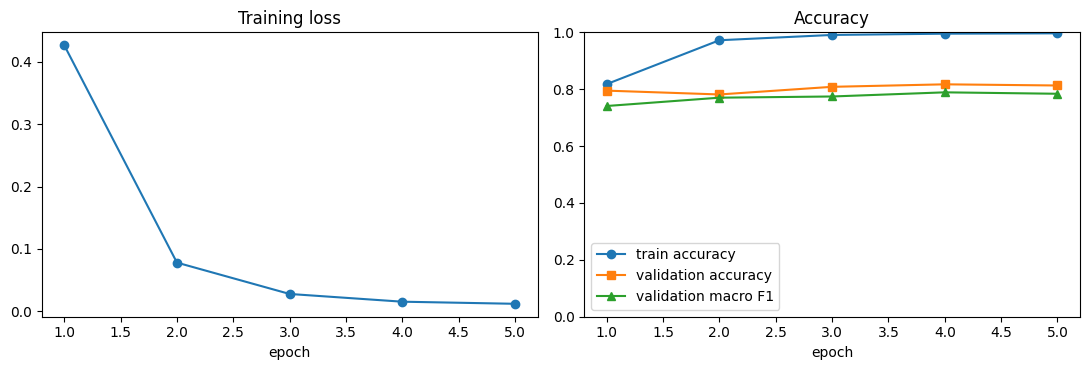

In [5]:
# ===== 5. Fine-tune ViT-B/16 (all layers) =====
import copy, time

EPOCHS, BS, LR = 5, 32, 3e-5
torch.manual_seed(0)
vit = load_vit().to(dev)                 # fresh pre-trained weights
dl_train = loader('train', TF_TRAIN, shuffle=True, bs=BS)
dl_val, dl_test = loader('val', TF_EVAL), loader('test', TF_EVAL)
n_cls = np.bincount(DATA['train'][1], minlength=3)
loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(n_cls.sum() / (3 * n_cls), dtype=torch.float32, device=dev))
opt = torch.optim.AdamW(vit.parameters(), lr=LR, weight_decay=0.05)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * len(dl_train), pct_start=0.1)
scaler = torch.amp.GradScaler(dev, enabled=(dev == 'cuda'))

@torch.no_grad()
def predict(dl):
    vit.eval()
    preds, probs = [], []
    for x, _ in dl:
        with torch.autocast(dev, dtype=torch.float16, enabled=(dev == 'cuda')):
            logits = vit(pixel_values=x.to(dev)).logits.float()
        probs.append(logits.softmax(1).cpu()); preds.append(logits.argmax(1).cpu())
    return torch.cat(preds).numpy(), torch.cat(probs).numpy()

history, best_f1, best_state = [], -1, None
for ep in range(1, EPOCHS + 1):
    vit.train(); t0 = time.time(); tot, correct = 0.0, 0
    for x, y in dl_train:
        x, y = x.to(dev), y.to(dev)
        with torch.autocast(dev, dtype=torch.float16, enabled=(dev == 'cuda')):
            logits = vit(pixel_values=x).logits
        loss = loss_fn(logits.float(), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item() * len(y); correct += (logits.argmax(1) == y).sum().item()
    vp, _ = predict(dl_val)
    h = {'epoch': ep, 'train loss': tot / len(DATA['train'][1]), 'train acc': correct / len(DATA['train'][1]),
         'val acc': accuracy_score(DATA['val'][1], vp), 'val macro F1': f1_score(DATA['val'][1], vp, average='macro')}
    history.append(h)
    print(f"epoch {ep}/{EPOCHS}  loss {h['train loss']:.4f}  train acc {h['train acc']:.3f}  "
          f"val acc {h['val acc']:.3f}  val macro F1 {h['val macro F1']:.3f}  ({time.time() - t0:.0f}s)")
    if h['val macro F1'] > best_f1:
        best_f1, best_state = h['val macro F1'], copy.deepcopy({k: v.cpu() for k, v in vit.state_dict().items()})

vit.load_state_dict(best_state)
hist = pd.DataFrame(history); hist.to_csv(OUTDIR / 'training_history.csv', index=False)
print(f"\nBest epoch {int(hist.loc[hist['val macro F1'].idxmax(), 'epoch'])} (validation macro F1 {best_f1:.3f})")
test_pred, test_prob = predict(dl_test)
record('ViT fine-tuned', test_pred)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(hist.epoch, hist['train loss'], 'o-'); ax[0].set_title('Training loss'); ax[0].set_xlabel('epoch')
ax[1].plot(hist.epoch, hist['train acc'], 'o-', label='train accuracy')
ax[1].plot(hist.epoch, hist['val acc'], 's-', label='validation accuracy')
ax[1].plot(hist.epoch, hist['val macro F1'], '^-', label='validation macro F1')
ax[1].set_ylim(0, 1); ax[1].set_xlabel('epoch'); ax[1].legend(); ax[1].set_title('Accuracy')
plt.tight_layout(); plt.savefig(OUTDIR / 'fig2_training_curves.png', dpi=150, bbox_inches='tight'); plt.show()
torch.save(vit.state_dict(), OUTDIR / 'vit_finetuned_state_dict.pt')

## 6. Evaluation on the test set
Test set: objects from videos never used for training or model selection. **Macro F1** (the average F1 over the three classes) is the main metric because the classes are imbalanced; accuracy alone would reward always predicting the most common class. A majority-class baseline is included for reference.


=== Majority class (reference): test accuracy 0.442, macro F1 0.204 ===
              precision    recall  f1-score   support

       trash      0.442     1.000     0.613       873
         bio      0.000     0.000     0.000       498
         rov      0.000     0.000     0.000       604

    accuracy                          0.442      1975
   macro avg      0.147     0.333     0.204      1975
weighted avg      0.195     0.442     0.271      1975

                            accuracy  macro F1  trash F1  bio F1  rov F1
method                                                                  
ViT frozen + linear            0.808     0.808     0.783   0.774   0.868
ViT fine-tuned                 0.856     0.855     0.841   0.832   0.894
Majority class (reference)     0.442     0.204     0.613   0.000   0.000


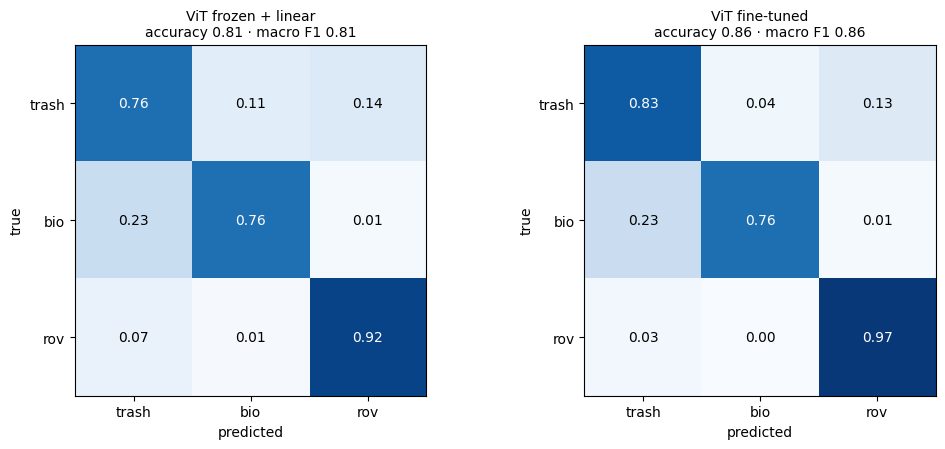

In [6]:
# ===== 6. Test-set evaluation: comparison table and confusion matrices =====
y = DATA['test'][1]
record('Majority class (reference)', np.full_like(y, np.bincount(DATA['train'][1]).argmax()))

rows = []
for name, r in RESULTS.items():
    row = {'method': name, 'accuracy': r['acc'], 'macro F1': r['f1']}
    for k, c in enumerate(NAMES):
        row[f'{c} precision'], row[f'{c} recall'], row[f'{c} F1'] = r['precision'][k], r['recall'][k], r['f1_class'][k]
    rows.append(row)
table = pd.DataFrame(rows).set_index('method').round(3)
print(table[['accuracy', 'macro F1'] + [f'{c} F1' for c in NAMES]])
table.to_csv(OUTDIR / 'test_results.csv')

show = [n for n in RESULTS if not n.startswith('Majority')]
fig, axes = plt.subplots(1, len(show), figsize=(5.2 * len(show), 4.6))
for ax, name in zip(np.atleast_1d(axes), show):
    cm = confusion_matrix(y, RESULTS[name]['pred'], labels=[0, 1, 2], normalize='true')
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', color='white' if cm[i, j] > 0.5 else 'black')
    ax.set_xticks(range(3), NAMES); ax.set_yticks(range(3), NAMES); ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title(f"{name}\naccuracy {RESULTS[name]['acc']:.2f} · macro F1 {RESULTS[name]['f1']:.2f}", fontsize=10)
plt.tight_layout(); plt.savefig(OUTDIR / 'fig3_confusion_matrices.png', dpi=150, bbox_inches='tight'); plt.show()

## 7. Performance and bias analysis
Where does the fine-tuned ViT do well or badly? Test objects are grouped by **object size** (small < 32 px, medium 32–96 px, large > 96 px), by **image clarity** (frame RMS contrast below / above the median = murky / clear), and by **source video**. Large differences between groups point to biases the model inherited from the data.

By object size:
                    objects  accuracy  macro F1
size group                                    
small (<32 px)         293     0.829     0.850
medium (32-96 px)      757     0.841     0.822
large (>96 px)         925     0.877     0.860 

By image clarity:
                        objects  accuracy  macro F1
clarity                                           
clear (high contrast)      990     0.835     0.822
murky (low contrast)       985     0.877     0.878

Per video (videos with >= 10 objects, n=43): accuracy mean 0.845, min 0.412, max 1.000, std 0.169


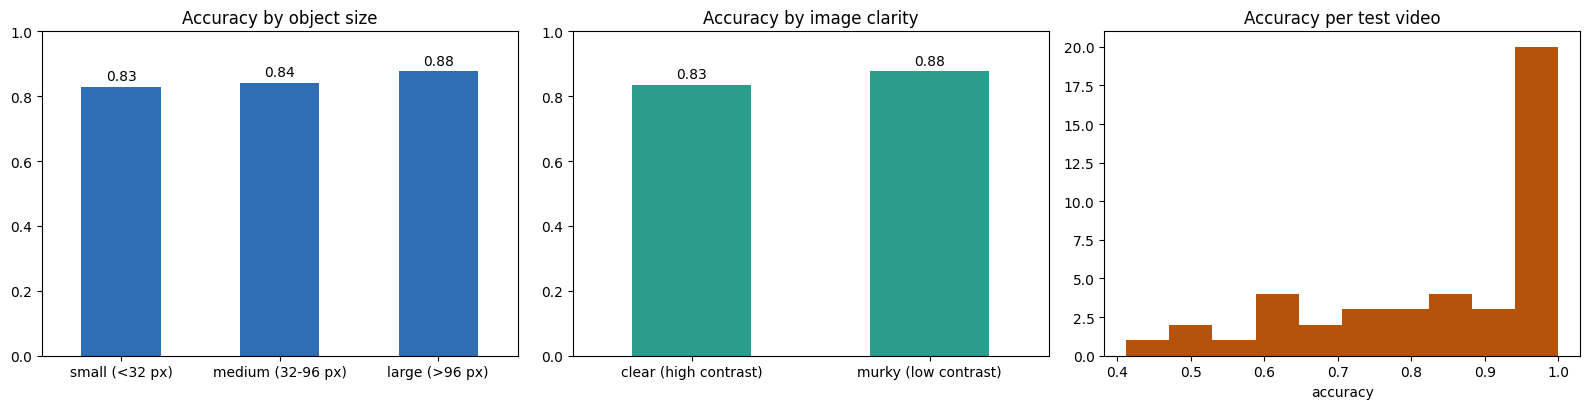

In [7]:
# ===== 7. Accuracy by object size, image clarity and video =====
test_meta = meta[meta.split == 'test'].reset_index(drop=True).copy()
test_meta['correct'] = RESULTS['ViT fine-tuned']['pred'] == test_meta.label.to_numpy()
test_meta['pred'] = RESULTS['ViT fine-tuned']['pred']
test_meta['size group'] = pd.cut(test_meta['size'], [0, 32, 96, 1e9], labels=['small (<32 px)', 'medium (32-96 px)', 'large (>96 px)'])
thr = test_meta.frame_contrast.median()          # median of the test frames -> two equal-sized groups
test_meta['clarity'] = np.where(test_meta.frame_contrast < thr, 'murky (low contrast)', 'clear (high contrast)')

def group_scores(col):
    out = []
    for g, d in test_meta.groupby(col, observed=True):
        out.append({col: g, 'objects': len(d), 'accuracy': d.correct.mean(),
                    'macro F1': f1_score(d.label, d.pred, average='macro', labels=[0, 1, 2], zero_division=0)})
    return pd.DataFrame(out).set_index(col).round(3)

by_size, by_clarity = group_scores('size group'), group_scores('clarity')
print('By object size:\n', by_size, '\n\nBy image clarity:\n', by_clarity)
per_video = test_meta.groupby('video').agg(objects=('correct', 'size'), accuracy=('correct', 'mean'))
per_video = per_video[per_video.objects >= 10]
print(f"\nPer video (videos with >= 10 objects, n={len(per_video)}): accuracy mean {per_video.accuracy.mean():.3f}, "
      f"min {per_video.accuracy.min():.3f}, max {per_video.accuracy.max():.3f}, std {per_video.accuracy.std():.3f}")
pd.concat({'size': by_size, 'clarity': by_clarity}).to_csv(OUTDIR / 'bias_analysis.csv')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
by_size['accuracy'].plot.bar(ax=ax[0], color='#2F6DB5'); ax[0].set_title('Accuracy by object size'); ax[0].set_ylim(0, 1)
by_clarity['accuracy'].plot.bar(ax=ax[1], color='#2A9D8F'); ax[1].set_title('Accuracy by image clarity'); ax[1].set_ylim(0, 1)
ax[2].hist(per_video.accuracy, bins=10, color='#B5530D'); ax[2].set_title('Accuracy per test video'); ax[2].set_xlabel('accuracy')
for a in ax[:2]:
    a.tick_params(axis='x', rotation=0); a.set_xlabel('')
    for i, v in enumerate(a.patches):
        a.text(v.get_x() + v.get_width() / 2, v.get_height() + 0.02, f'{v.get_height():.2f}', ha='center')
plt.tight_layout(); plt.savefig(OUTDIR / 'fig4_bias_analysis.png', dpi=150, bbox_inches='tight'); plt.show()

## 8. Explainability: where does the ViT look?
**Attention rollout** (Abnar & Zuidema, 2020) multiplies the attention matrices of all 12 layers to estimate which patches the [CLS] token relies on. The second figure shows the fine-tuned ViT's most confident **mistakes**, which help explain its errors.

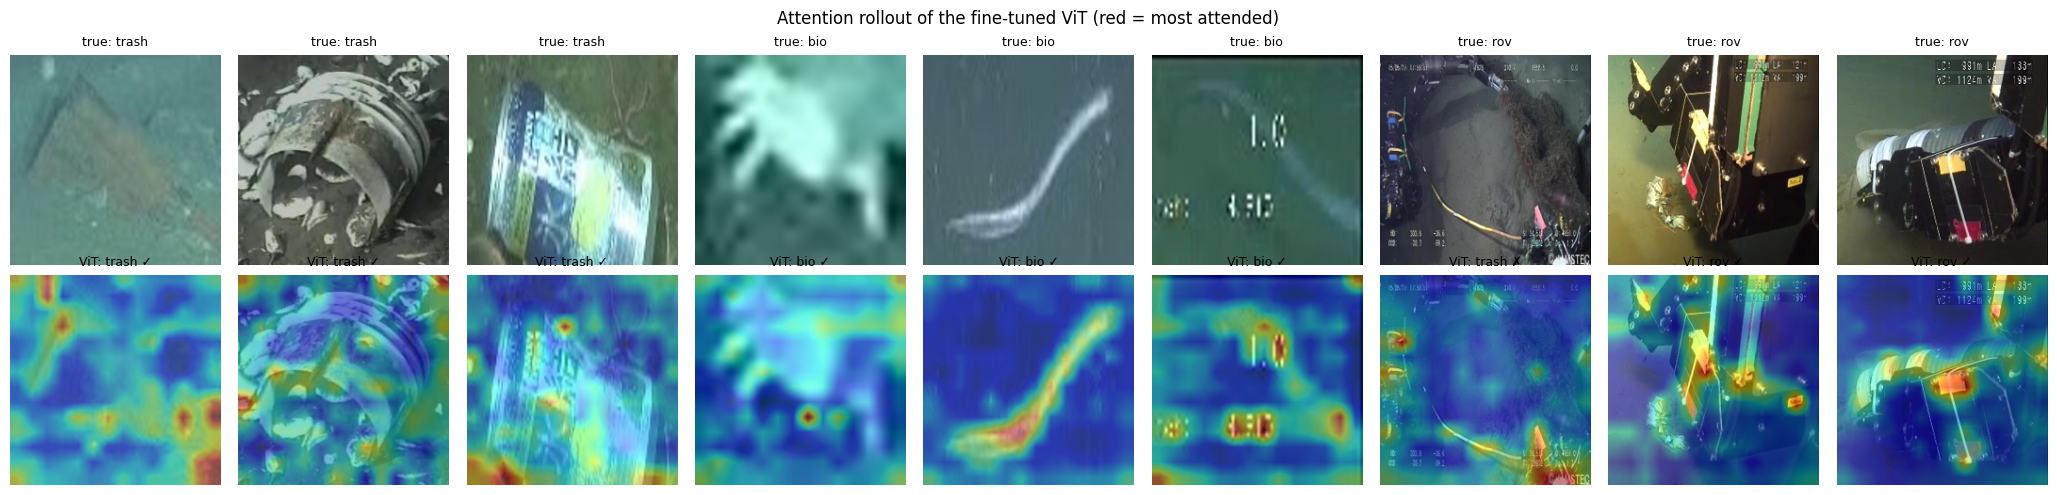

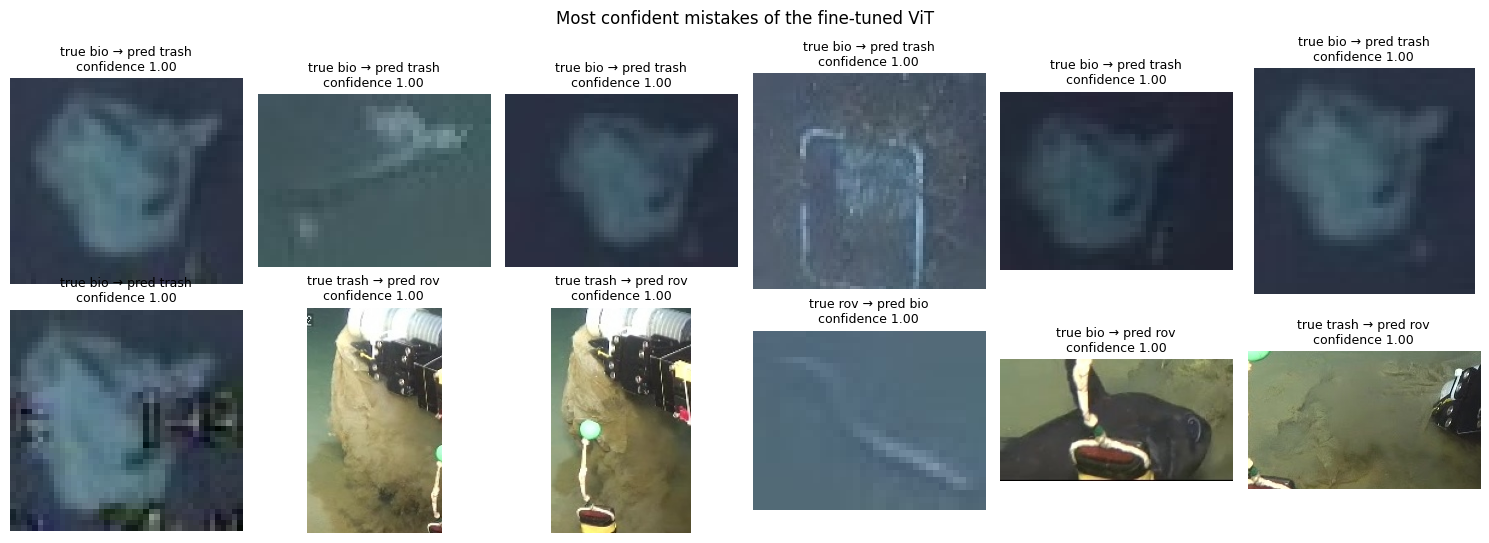

Figures saved to /content/drive/MyDrive/OceanWatch/vit_report


In [8]:
# ===== 8. Attention rollout and the model's mistakes =====
@torch.no_grad()
def rollout(x):
    vit.eval()
    out = vit(pixel_values=x[None].to(dev), output_attentions=True)
    if not out.attentions or out.attentions[0] is None:
        return None
    att = torch.stack(out.attentions).squeeze(1).mean(1).float()     # layers x tokens x tokens (heads averaged)
    att = att + torch.eye(att.size(-1), device=att.device)
    att = att / att.sum(-1, keepdim=True)
    R = att[0]
    for a in att[1:]:
        R = a @ R
    m = R[0, 1:].reshape(14, 14).cpu().numpy()
    return m / m.max()

files = DATA['test'][0]
rng = np.random.default_rng(1)
pick = np.concatenate([rng.choice(np.where(y == k)[0], 3, replace=False) for k in range(3)])
fig, axes = plt.subplots(2, len(pick), figsize=(2.3 * len(pick), 5))
for j, i in enumerate(pick):
    img = Image.open(files[i]).convert('RGB')
    m = rollout(TF_EVAL(img))
    axes[0, j].imshow(img.resize((224, 224))); axes[0, j].axis('off')
    axes[0, j].set_title(f'true: {NAMES[y[i]]}', fontsize=9)
    axes[1, j].imshow(img.resize((224, 224)))
    if m is not None:
        axes[1, j].imshow(cv2.resize(m, (224, 224)), cmap='jet', alpha=0.45)
    pr = RESULTS['ViT fine-tuned']['pred'][i]
    axes[1, j].set_title(f"ViT: {NAMES[pr]} {'✓' if pr == y[i] else '✗'}", fontsize=9); axes[1, j].axis('off')
plt.suptitle('Attention rollout of the fine-tuned ViT (red = most attended)')
plt.tight_layout(); plt.savefig(OUTDIR / 'fig5_attention_maps.png', dpi=150, bbox_inches='tight'); plt.show()

wrong = np.where(test_pred != y)[0]
wrong = wrong[np.argsort(-test_prob[wrong].max(1))][:12]
if len(wrong):
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.5))
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, wrong):
        ax.imshow(Image.open(files[i]).convert('RGB'))
        ax.set_title(f'true {NAMES[y[i]]} → pred {NAMES[test_pred[i]]}\nconfidence {test_prob[i].max():.2f}', fontsize=9)
    plt.suptitle('Most confident mistakes of the fine-tuned ViT')
    plt.tight_layout(); plt.savefig(OUTDIR / 'fig6_mistakes.png', dpi=150, bbox_inches='tight'); plt.show()
print('Figures saved to', OUTDIR)

## 9. (Optional) CLIP zero-shot comparison
CLIP (Radford et al., 2021) is a multimodal vision-language transformer. Here it classifies the same test crops **without any training**, only from text prompts, as a point of comparison for the fine-tuned ViT.

In [9]:
# ===== 9. (Optional) CLIP zero-shot on the same test crops =====
from transformers import CLIPModel, CLIPProcessor
CLIP_ID = 'openai/clip-vit-base-patch32'
clip, proc = CLIPModel.from_pretrained(CLIP_ID).to(dev).eval(), CLIPProcessor.from_pretrained(CLIP_ID)

def _vec(out, kind):
    if torch.is_tensor(out):
        return out
    v = getattr(out, f'{kind}_embeds', None)
    return v if v is not None else out.pooler_output

PROMPTS = {'trash': ['a photo of plastic trash underwater', 'a photo of litter on the sea floor',
                     'a photo of a discarded bag, bottle or can underwater', 'a photo of marine debris'],
           'bio': ['a photo of a fish', 'a photo of a sea animal such as a crab, starfish or eel',
                   'a photo of an underwater plant', 'a photo of marine life on the sea floor'],
           'rov': ['a photo of a robot arm', 'a photo of an underwater robot',
                   'a photo of the metal frame of an underwater vehicle', 'a photo of a remotely operated vehicle part']}
with torch.no_grad():
    T = []
    for c in NAMES:
        t = proc(text=PROMPTS[c], return_tensors='pt', padding=True).to(dev)
        e = torch.nn.functional.normalize(_vec(clip.get_text_features(**t), 'text').float(), dim=-1).mean(0)
        T.append(torch.nn.functional.normalize(e, dim=0))
    T = torch.stack(T)
    preds = []
    for i in range(0, len(files), 128):
        x = proc(images=[Image.open(f).convert('RGB') for f in files[i:i + 128]], return_tensors='pt')['pixel_values'].to(dev)
        e = torch.nn.functional.normalize(_vec(clip.get_image_features(pixel_values=x), 'image').float(), dim=-1)
        preds.append((e @ T.T).argmax(1).cpu())
record('CLIP zero-shot (no training)', torch.cat(preds).numpy())

rows = [{'method': n, 'accuracy': r['acc'], 'macro F1': r['f1'], **{f'{c} F1': r['f1_class'][k] for k, c in enumerate(NAMES)}}
        for n, r in RESULTS.items()]
final = pd.DataFrame(rows).set_index('method').round(3)
print(final); final.to_csv(OUTDIR / 'test_results.csv')

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]


=== CLIP zero-shot (no training): test accuracy 0.589, macro F1 0.585 ===
              precision    recall  f1-score   support

       trash      0.780     0.346     0.479       873
         bio      0.484     0.767     0.593       498
         rov      0.600     0.793     0.683       604

    accuracy                          0.589      1975
   macro avg      0.621     0.635     0.585      1975
weighted avg      0.650     0.589     0.570      1975

                              accuracy  macro F1  trash F1  bio F1  rov F1
method                                                                    
ViT frozen + linear              0.808     0.808     0.783   0.774   0.868
ViT fine-tuned                   0.856     0.855     0.841   0.832   0.894
Majority class (reference)       0.442     0.204     0.613   0.000   0.000
CLIP zero-shot (no training)     0.589     0.585     0.479   0.593   0.683


## 10. Export for the web app (Streamlit / GitHub)
Saves everything the deployed app needs to **Google Drive → OceanWatch → vit_report → deploy**: the fine-tuned ViT in half precision (~170 MB, for the GitHub Release), 12 labelled test images (the true class is in the file name) and the test results table. Runs in under a minute.

In [10]:
# ===== 10. Export files for the Streamlit app =====
DEPLOY = OUTDIR / 'deploy'
DEPLOY.mkdir(exist_ok=True)

# 1. Fine-tuned ViT weights in float16 (half the size; the app converts back to float32)
torch.save({k: v.half() if v.is_floating_point() else v for k, v in vit.state_dict().items()},
           DEPLOY / 'vit_b16_trashcan_fp16.pt')

# 2. Test results table
shutil.copy2(OUTDIR / 'test_results.csv', DEPLOY / 'test_results.csv')

# 3. Twelve test crops (4 per class), true class in the file name: sample__<class>__<name>.jpg
rng = np.random.default_rng(7)
for k, c in enumerate(NAMES):
    idx = np.where(DATA['test'][1] == k)[0]
    for i in rng.choice(idx, min(4, len(idx)), replace=False):
        f = Path(DATA['test'][0][i])
        shutil.copy2(f, DEPLOY / f'sample__{c}__{f.name}')

for f in sorted(DEPLOY.iterdir()):
    print(f'{f.name:<60} {f.stat().st_size / 1e6:8.2f} MB')
print('\nSaved to Google Drive:', DEPLOY)


sample__bio__vid_000053_frame0000014_2884.jpg                    0.00 MB
sample__bio__vid_000102_frame0000012_525.jpg                     0.00 MB
sample__bio__vid_000102_frame0000023_3963.jpg                    0.00 MB
sample__bio__vid_000102_frame0000023_3971.jpg                    0.00 MB
sample__rov__vid_000126_frame0000025_10291.jpg                   0.01 MB
sample__rov__vid_000143_frame0000057_10381.jpg                   0.03 MB
sample__rov__vid_000143_frame0000070_6961.jpg                    0.01 MB
sample__rov__vid_000155_frame0000030_1882.jpg                    0.03 MB
sample__trash__vid_000079_frame0000008_11346.jpg                 0.00 MB
sample__trash__vid_000079_frame0000014_10690.jpg                 0.00 MB
sample__trash__vid_000089_frame0000047_7256.jpg                  0.01 MB
sample__trash__vid_000553_frame0000034_7976.jpg                  0.00 MB
test_results.csv                                                 0.00 MB
vit_b16_trashcan_fp16.pt                           